In [1]:
# imports and configrations

In [2]:
from langsmith import Client
from pathlib import Path
from dotenv import load_dotenv
import langsmith as ls
import os

In [3]:
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage, SystemMessage, BaseMessage, AIMessage, ToolMessage
from langchain.tools import tool
from langgraph.graph import StateGraph, START, END, add_messages
from langgraph.prebuilt import ToolNode, tools_condition

from typing import TypedDict, Literal, Annotated
from typing_extensions import NotRequired

from pydantic import BaseModel, Field
from rich import print

In [4]:
# Robust .env discovery
env_path = None
for parent in [Path.cwd()] + list(Path.cwd().parents):
    candidate = parent / ".env"
    if candidate.is_file():
        env_path = candidate
        break

if env_path:
    load_dotenv(env_path)

openai_api_key = os.getenv("OPENAI_API_KEY")
langsmith_api_key = os.getenv("LANGSMITH_API_KEY")

In [5]:
os.environ["LANGSMITH_PROJECT"] = "router-agent"
os.environ["LANGCHAIN_PROJECT"] = "router-agent"
os.environ["LANGCHAIN_TRACING_V2"] = "true" 

In [6]:
# business logic

In [7]:
model = ChatOpenAI(
    model="gpt-4.1-mini",
    api_key=openai_api_key,
    temperature=0
)

In [8]:
class State(BaseModel):
    messages: Annotated[list[BaseMessage], add_messages] = Field(
        default_factory=list, 
        description="Contains all the conversation messages."
    )
    user_question: str = Field(
        default="", 
        description="Contains the user query"
    )
    type: Literal["maths", "sql", "research", "general"] | None = Field(
        default=None, 
        description="This field defines the query type"
    )
    result: str = Field(
        default="", 
        description="This field contains the final response generated by the specialised agent against the user query"
    )

In [9]:
class QueryType(BaseModel):
    type: Literal["maths", "sql", "research", "general"] = Field(
        description="Classify the query into: 'maths' (mathematics/calculations), 'sql' (SQL/database operations), 'research' (in-depth analysis/research), or 'general' (everyday chat/general questions)"
    )

In [10]:
query_classifier_model = model.with_structured_output(QueryType)

def query_classifier_agent(state: State):
    user_query = state.user_question or (state.messages[-1].content if state.messages else "")
    human_message = HumanMessage(content=user_query)

    # Classifies the question type the user is asking
    classification = query_classifier_model.invoke([human_message])

    return {
        "type": classification.type,
        "user_question": user_query,
        "messages": [human_message] if not state.messages else []
    }

In [11]:
def router(state: State) -> Literal["maths", "sql", "research", "general"]:
    query_type = state.type

    if query_type in ["maths", "sql", "research", "general"]:
        return query_type

    return "general"

In [12]:
def mathematical_agent(state: State):
    user_query = state.user_question
    system_prompt = "You are a helpful mathematical agent, specialized in solving mathematical and arithmetic problems with clear step-by-step explanations."
    system_message = SystemMessage(content=system_prompt)
    human_message = HumanMessage(content=user_query)

    messages = [system_message, human_message]

    # Generates the final response for the user query
    result = model.invoke(messages)

    return {
        "result": result.content,
        "messages": [result]
    }

In [13]:
def sql_agent(state: State):
    user_query = state.user_question
    system_prompt = "You are a helpful SQL expert agent, specialized in designing database schemas, writing optimized SQL queries, and explaining database concepts."
    system_message = SystemMessage(content=system_prompt)
    human_message = HumanMessage(content=user_query)

    messages = [system_message, human_message]

    # Generates the final response for the user query
    result = model.invoke(messages)

    return {
        "result": result.content,
        "messages": [result]
    }

In [14]:
def research_agent(state: State):
    user_query = state.user_question
    system_prompt = "You are a helpful research agent, specialized in comprehensive analysis, comparative evaluations, and structured research synthesis."
    system_message = SystemMessage(content=system_prompt)
    human_message = HumanMessage(content=user_query)

    messages = [system_message, human_message]

    # Generates the final response for the user query
    result = model.invoke(messages)

    return {
        "result": result.content,
        "messages": [result]
    }

In [15]:
def general_purpose_agent(state: State):
    user_query = state.user_question
    system_prompt = "You are a friendly and helpful general-purpose assistant, specialized in answering everyday questions, facts, and engaging in open conversation."
    system_message = SystemMessage(content=system_prompt)
    human_message = HumanMessage(content=user_query)

    messages = [system_message, human_message]

    # Generates the final response for the user query
    result = model.invoke(messages)

    return {
        "result": result.content,
        "messages": [result]
    }

In [16]:
# defining Graph

In [17]:
graph = StateGraph(State)

# 1. Defining all nodes
graph.add_node("query_classifier_agent", query_classifier_agent)
graph.add_node("mathematical_agent", mathematical_agent)
graph.add_node("sql_agent", sql_agent)
graph.add_node("research_agent", research_agent)
graph.add_node("general_purpose_agent", general_purpose_agent)

# 2. Defining entry edge
graph.add_edge(START, "query_classifier_agent")

# 3. Defining conditional routing edges
graph.add_conditional_edges(
    "query_classifier_agent",
    router,
    {
        "maths": "mathematical_agent",
        "sql": "sql_agent",
        "research": "research_agent",
        "general": "general_purpose_agent"
    }
)

# 4. Connecting each specialized agent to END
graph.add_edge("mathematical_agent", END)
graph.add_edge("sql_agent", END)
graph.add_edge("research_agent", END)
graph.add_edge("general_purpose_agent", END)

# 5. Compile workflow
workflow = graph.compile()

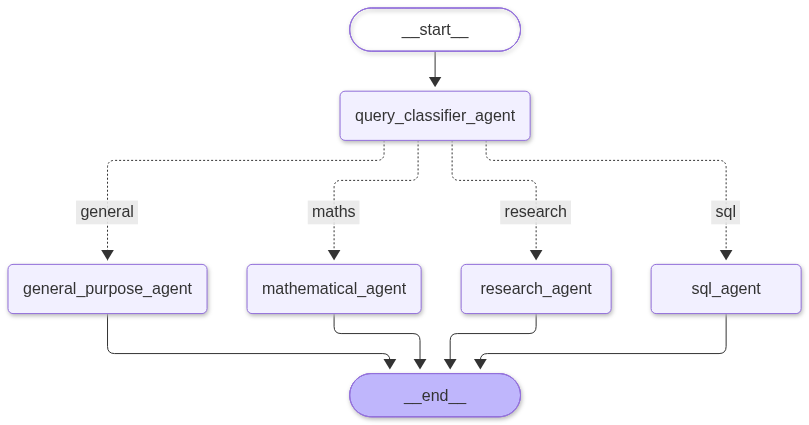

In [18]:
workflow

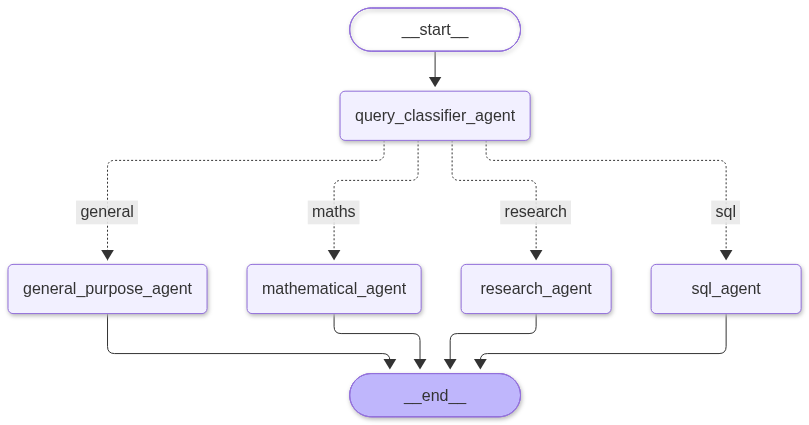

In [19]:
from IPython.display import Image, display

try:
    display(Image(workflow.get_graph().draw_mermaid_png()))
except Exception:
    print(workflow.get_graph().draw_mermaid())

In [19]:
test_queries = [
    "What is the derivative of x^3 + 5x - 7?",
    "Write a SQL query to select all employees with salary > 50000 ordered by joining date.",
    "Compare the architectural tradeoffs between microservices and event-driven architectures.",
    "Hello! How are you doing today and what can you help me with?"
]

for query in test_queries:
    print(f"\n{'='*60}")
    print(f"User Query: {query}")
    print(f"{'='*60}")
    
    initial_state = State(user_question=query)
    response = workflow.invoke(initial_state)
    
    print(f"🏷️  Classified Query Type : {response['type']}")
    print(f"🤖 Specialized Response  :\n{response['result']}\n")

============================================================

User Query: What is the derivative of x^3 + 5x - 7?

============================================================

🏷️  Classified Query Type : maths

🤖 Specialized Response  :
To find the derivative of the function \( f(x) = x^3 + 5x - 7 \), we differentiate each term separately:

1. The derivative of \( x^3 \) is \( 3x^2 \).
2. The derivative of \( 5x \) is \( 5 \).
3. The derivative of the constant \( -7 \) is \( 0 \).

Putting it all together:

[
f'(x) = 3x^2 + 5 + 0 = 3x^2 + 5
\]

**Answer:**

[
\boxed{3x^2 + 5}
\]

============================================================

... (10 outputs left out)

User Query: Hello! How are you doing today and what can you help me with?

============================================================

🏷️  Classified Query Type : general

🤖 Specialized Response  :
Hello! I'm doing great, thank you for asking. How about you? I can help with a wide range of things—answering 
questions, providing information, helping with writing or brainstorming, offering recommendations, and much more. 
What do you need help with today?